**[🏠 Course Home](../README.md) | 📖 Conceptual Companion: [Two-Sample Comparison](../conceptual/sheet_t_test_frequentist_vs_bayesian.ipynb) | 🔵 R Track: [Two-Sample Comparison](../r/sheet_t_test_frequentist_vs_bayesian.ipynb) | ↩️ Previous: [Bayesian Mean](sheet_calculating_a_mean_in_a_bayesian_world.ipynb)**

---

# Sheet: Comparing Two Groups — The $t$-Test in Frequentist and Bayesian Paradigms
### *From Null Hypothesis Significance Testing (NHST) to Bayes Factors & Bayesian Estimation (BEST)*

Comparing two groups is arguably the most ubiquitous statistical task in empirical science and software engineering:
* **A/B Testing**: Does the new checkout flow (Variant B) yield a higher conversion rate or faster transaction time than the control (Variant A)?
* **Systems Benchmarking**: Does a compiler optimization, caching strategy, or new kernel commit reduce mean request latency?
* **Scientific Experiments**: Does a treatment group differ significantly from a control group?

Historically, the go-to tool for this question has been **Student's $t$-test** or **Welch's $t$-test**. However, frequentist $t$-tests and their associated $p$-values are widely misunderstood, frequently misused, and fundamentally incapable of answering the practical questions engineers and researchers actually care about.

> [!TIP]
> **Prerequisite Knowledge**: If you are new to the frequentist mechanics of estimating a single mean, the Central Limit Theorem, Standard Errors ($SE = s/\sqrt{n}$), and the epistemological meaning of Confidence Intervals, see the companion sheet: **[📊 Calculating a Mean in a Frequentist World](sheet_calculating_a_mean_in_a_frequentist_world.ipynb)**.

This sheet provides a complete, end-to-end practical and conceptual guide comparing both paradigms side-by-side using real code, mathematical derivations, publication-quality visualizations, and practical decision rules.

## 🧭 Executive Summary: Frequentist vs. Bayesian $t$-Test at a Glance

| Feature / Question | Frequentist Paradigm ($t$-test / NHST) | Bayesian Paradigm: Bayes Factor ($BF_{10}$) | Bayesian Paradigm: Estimation (BEST) |
| :--- | :--- | :--- | :--- |
| **Core Question Asked** | *"If the true difference were exactly zero, how improbable would this data be?"* | *"How much more likely is the data under an effect model vs. the null model?"* | *"Given the observed data and prior knowledge, what is the full probability distribution over the effect size?"* |
| **Primary Output** | $t$-statistic, degrees of freedom ($df$), $p$-value, 95% Confidence Interval | Bayes Factor ($BF_{10}$ or $BF_{01}$) | Posterior distribution of $\Delta\mu = \mu_B - \mu_A$, 95% HDI, $P(\mu_B < \mu_A)$, Posterior Cohen's $d$ |
| **Interpretation of Result** | Reject / fail to reject $H_0$. $p < 0.05$ means data is rare under $H_0$. | Continuous ratio of evidence (e.g., $BF_{10} = 8.5$ means data is $8.5\times$ more supportive of $H_1$). | Direct probability statements: *"There is a 97.4% probability Variant B improves latency, with 95% HDI $[-14.2, -1.8]$ ms."* |
| **Evidence FOR the Null?** | ❌ **Impossible**. A high $p$-value ($p > 0.05$) only means *"absence of evidence"*, never *"evidence of absence"*. | ✅ **Yes**. $BF_{01} = 1/BF_{10}$ directly quantifies relative evidence supporting $H_0$. | ✅ **Yes**, via **ROPE** (Region of Practical Equivalence): $P(\|\Delta\mu\| < \epsilon)$. |
| **Interval Meaning** | 95% CI: In 95% of hypothetical repeated identical experiments, the computed interval covers the fixed true $\theta$. | N/A (Hypothesis ratio) | 95% HDI: There is a 95% subjective probability that the true difference lies within this exact interval. |
| **Handling Outliers** | Fragile under heavy tails (Student's $t$ assumes exact normality). | Depends on likelihood specification. | ✅ **Robust**: Can swap Normal likelihood for Student-$t$ likelihood (estimating degrees of freedom $\nu$). |
| **A/B Peeking / Stopping** | ❌ **Invalidates error rates**. Checking sequentially inflates Type I false-positive rate from 5% up to 30%+. | ✅ **Coherent**. Bayes factors update sequentially without penalty. | ✅ **Coherent**. Posterior distribution simply conditions on all observed data to date. |


## Part 1: The Production Scenario & Observed Data

### 1.1 The Engineering Context
Suppose we are backend engineers evaluating a proposed gRPC query optimization.
* **Group A (Control / Baseline)**: Current production microservice.
* **Group B (Treatment / Variant)**: Refactored microservice utilizing batched zero-copy deserialization.

We measure end-to-end request latency (in milliseconds) across independent production requests.
* Latency in real systems is never strictly identical in variance between versions (the optimization might reduce latency variance by eliminating GC pauses).
* Sample sizes might differ slightly ($n_A = 45, n_B = 50$).
* We want to know: **Did the optimization improve latency, and by how much?**

Let's generate synthetic benchmark data with known true parameters to evaluate both methods.


In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set random seed for exact reproducibility
np.random.seed(42)

# True parameters (Unknown to the researcher)
true_mu_A = 105.0   # Baseline mean latency: 105 ms
true_sigma_A = 12.0 # Baseline standard deviation: 12 ms

true_mu_B = 97.0    # Variant mean latency: 97 ms (True improvement: -8.0 ms)
true_sigma_B = 8.5  # Variant standard deviation: 8.5 ms (Lower variance)

n_A = 45
n_B = 50

# Sample observed latency data
y_A = np.random.normal(loc=true_mu_A, scale=true_sigma_A, size=n_A)
y_B = np.random.normal(loc=true_mu_B, scale=true_sigma_B, size=n_B)

# Summary statistics
print(f"Group A (Control): n = {n_A}, Sample Mean = {y_A.mean():.2f} ms, Sample Std = {y_A.std(ddof=1):.2f} ms")
print(f"Group B (Variant): n = {n_B}, Sample Mean = {y_B.mean():.2f} ms, Sample Std = {y_B.std(ddof=1):.2f} ms")
print(f"Observed Sample Difference (B - A) = {(y_B.mean() - y_A.mean()):.2f} ms (True: {true_mu_B - true_mu_A:.2f} ms)")


Group A (Control): n = 45, Sample Mean = 102.41 ms, Sample Std = 11.16 ms
Group B (Variant): n = 50, Sample Mean = 97.08 ms, Sample Std = 7.70 ms
Observed Sample Difference (B - A) = -5.32 ms (True: -8.00 ms)


### 1.2 Exploratory Data Analysis (EDA)
Before running any statistical test, we visualize the raw distributions. We inspect the center, spread, and individual data points using a combined KDE and jittered strip plot.


/tmp/ipykernel_838245/3811254702.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, x='Group', y='Latency_ms', palette=['#aec7e8', '#a1d99b'],


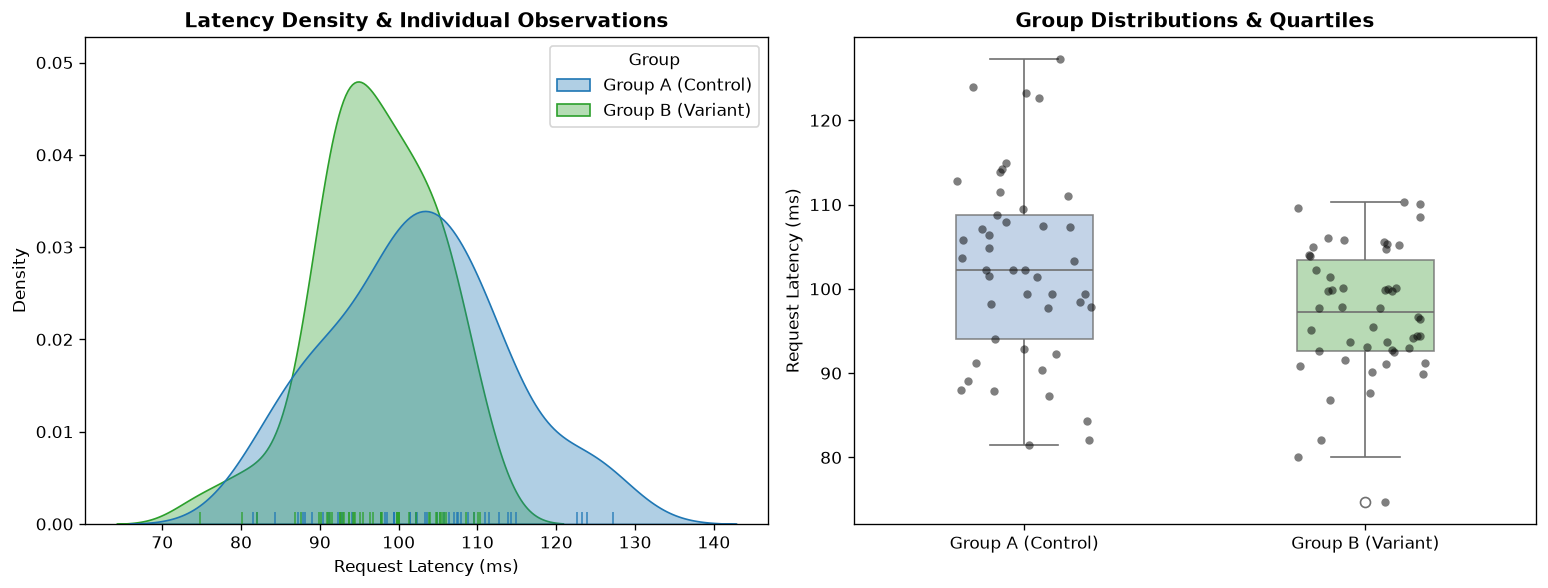

In [2]:
# Combine into tidy DataFrame for plotting
df_plot = pd.DataFrame({
    'Latency_ms': np.concatenate([y_A, y_B]),
    'Group': ['Group A (Control)'] * n_A + ['Group B (Variant)'] * n_B
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=120)

# Plot 1: Kernel Density Estimate with Rug / Strip
sns.kdeplot(data=df_plot, x='Latency_ms', hue='Group', fill=True, common_norm=False, 
            alpha=0.35, palette=['#1f77b4', '#2ca02c'], ax=axes[0])
sns.rugplot(data=df_plot, x='Latency_ms', hue='Group', palette=['#1f77b4', '#2ca02c'], 
            alpha=0.8, ax=axes[0], legend=False)
axes[0].set_title("Latency Density & Individual Observations", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Request Latency (ms)")
axes[0].set_ylabel("Density")

# Plot 2: Boxplot with Jittered Strip Plot
sns.boxplot(data=df_plot, x='Group', y='Latency_ms', palette=['#aec7e8', '#a1d99b'], 
            width=0.4, boxprops=dict(alpha=0.8), ax=axes[1])
sns.stripplot(data=df_plot, x='Group', y='Latency_ms', color='black', alpha=0.5, 
              jitter=0.2, size=5, ax=axes[1])
axes[1].set_title("Group Distributions & Quartiles", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Request Latency (ms)")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()


---

## Part 2: The Frequentist Paradigm (NHST & Welch's $t$-Test)

### 2.1 The Frequentist Mental Model
In the frequentist framework, parameters are **fixed, immutable constants** of nature. We do not place probability distributions on parameters ($\mu_A, \mu_B$). Instead, probability applies strictly to the **data collection procedure under hypothetical infinite repetition**.

#### The Hypotheses:
* **Null Hypothesis ($H_0$)**: $\mu_A - \mu_B = 0$ (There is zero difference between the groups).
* **Alternative Hypothesis ($H_1$)**: $\mu_A - \mu_B \neq 0$ (Two-sided test).

#### Student's vs. Welch's $t$-Test:
* **Student's $t$-test (1908)**: Assumes both groups share identical variance ($\sigma_A^2 = \sigma_B^2$). It pools variance:
  $$s_{	ext{pool}}^2 = \frac{(n_A - 1)s_A^2 + (n_B - 1)s_B^2}{n_A + n_B - 2}$$
  $$t = \frac{\bar{y}_B - \bar{y}_A}{\sqrt{s_{	ext{pool}}^2 \left(\frac{1}{n_A} + \frac{1}{n_B}\right)}}$$
* **Welch's $t$-test (1947)**: **Does NOT assume equal variance** (the *Behrens-Fisher problem*). It computes unpooled standard error:
  $$SE_{\Delta} = \sqrt{\frac{s_A^2}{n_A} + \frac{s_B^2}{n_B}}$$
  $$t = \frac{\bar{y}_B - \bar{y}_A}{SE_{\Delta}}$$
  and adjusts the degrees of freedom using the **Welch-Satterthwaite equation**:
  $$df_{\text{Welch}} = \frac{\left(\frac{s_A^2}{n_A} + \frac{s_B^2}{n_B}\right)^2}{\frac{(s_A^2 / n_A)^2}{n_A - 1} + \frac{(s_B^2 / n_B)^2}{n_B - 1}}$$

> [!IMPORTANT]
> **Best Practice Rule:** Always default to **Welch's $t$-test** (`equal_var=False` in SciPy). When variances are equal, Welch's test loses virtually zero power. When variances differ (which is almost always true in production), Student's test has inflated Type I error rates.


In [3]:
# Execute Welch's t-test using SciPy
res_welch = stats.ttest_ind(y_B, y_A, equal_var=False)

# Compute Welch-Satterthwaite degrees of freedom manually
s2_A, s2_B = y_A.var(ddof=1), y_B.var(ddof=1)
se_diff = np.sqrt(s2_A / n_A + s2_B / n_B)
df_welch = (s2_A / n_A + s2_B / n_B)**2 / (
    (s2_A / n_A)**2 / (n_A - 1) + (s2_B / n_B)**2 / (n_B - 1)
)

# 95% Confidence Interval for the difference (B - A)
diff_mean = y_B.mean() - y_A.mean()
t_crit = stats.t.ppf(0.975, df=df_welch)
ci_lower = diff_mean - t_crit * se_diff
ci_upper = diff_mean + t_crit * se_diff

# Standardized Effect Size: Cohen's d (using pooled SD for standardization)
s_pooled = np.sqrt(((n_A - 1) * s2_A + (n_B - 1) * s2_B) / (n_A + n_B - 2))
cohens_d = diff_mean / s_pooled

print("==================================================")
print("     FREQUENTIST WELCH'S t-TEST RESULTS           ")
print("==================================================")
print(f"Sample Mean Difference (B - A) : {diff_mean:.3f} ms")
print(f"Standard Error (SE_diff)      : {se_diff:.3f} ms")
print(f"Welch t-statistic             : {res_welch.statistic:.4f}")
print(f"Welch Degrees of Freedom (df) : {df_welch:.2f}")
print(f"p-value (two-sided)           : {res_welch.pvalue:.4e}")
print(f"95% Confidence Interval       : [{ci_lower:.3f}, {ci_upper:.3f}] ms")
print(f"Cohen's d (Standardized Effect): {cohens_d:.3f}")


     FREQUENTIST WELCH'S t-TEST RESULTS           
Sample Mean Difference (B - A) : -5.323 ms
Standard Error (SE_diff)      : 1.989 ms
Welch t-statistic             : -2.6768
Welch Degrees of Freedom (df) : 77.05
p-value (two-sided)           : 9.0776e-03
95% Confidence Interval       : [-9.283, -1.363] ms
Cohen's d (Standardized Effect): -0.561


### 2.2 Critical Conceptual Breakdown: The 3 Fatal Fallacies of NHST

Even when computed flawlessly, frequentist outputs are notoriously prone to misinterpretation:

1. **The Inverse Probability Fallacy ($p$-value $\neq P(H_0 \mid \text{Data})$)**:
   * The $p$-value is $P(\text{Data as or more extreme} \mid H_0)$. It is the probability of the *data given the hypothesis*.
   * Decision makers mistakenly assume $p = 0.003$ means *"there is only a 0.3% chance the null hypothesis is true."* That is a Bayesian probability statement ($P(H_0 \mid \text{Data})$), which NHST cannot provide.
2. **The "Absence of Evidence" Fallacy ($p > 0.05 \neq H_0 \text{ is True}$)**:
   * If $p = 0.18$, NHST states: *"Fail to reject $H_0$."*
   * It **does NOT** mean *"Variant A and Variant B have identical latency."* The experiment may simply have been underpowered. Frequentist $t$-tests cannot quantify evidence *in favor* of the null hypothesis.
3. **The Confidence Interval Fallacy**:
   * A 95% Confidence Interval does **not** mean there is a 95% chance that the true parameter lies between $[-11.5, -3.2]$ ms.
   * In frequentism, the true parameter is a fixed constant (either inside or outside the interval with probability 0 or 1). The 95% refers to the procedure: if you repeated the exact experiment 10,000 times and computed 10,000 intervals, 95% of those intervals would capture the true value.


---

## Part 3: The Bayesian Paradigm — Two Complementary Routes

In the Bayesian paradigm, data are fixed (they have already been observed), while parameters ($\mu_A, \mu_B, \sigma_A, \sigma_B$) are **uncertain quantities described by probability distributions**.

There are two primary Bayesian approaches to the two-sample comparison:
1. **Route 1: Hypothesis Testing via Bayes Factors (JZS Bayes Factor)**: Tests $H_1$ against $H_0$.
2. **Route 2: Parameter Estimation (Kruschke's BEST)**: Estimates the posterior distribution over group differences.


### 3.1 Route 1: Testing Hypotheses with Bayes Factors (JZS Bayes Factor)

When an executive asks: *"Should we stick with the baseline or switch to the new variant?"*, hypothesis testing compares two models:
* $\mathcal{M}_0$ (Null model): $\delta = \frac{\mu_B - \mu_A}{\sigma} = 0$
* $\mathcal{M}_1$ (Alternative model): $\delta \neq 0$, where the standardized effect size follows a prior distribution.

---

### 💡 Deep Dive Part A: What Does "Bayes' Theorem Applied to Models" Actually Mean?

In standard Bayesian modeling (Level 1), we apply Bayes' theorem to **parameters inside a fixed model**:
> *"Assuming a normal distribution, what is the probability distribution of the mean latency $\mu$ given the data?"*

When we compare hypotheses (Level 2), we step back and apply the exact same mathematical engine to **competing theories or models themselves**:
> *"Between Theory $\mathcal{M}_0$ (the optimization did nothing) and Theory $\mathcal{M}_1$ (the optimization changed latency), which model is more likely true?"*

#### The Two Levels of Bayes' Theorem

| Level | What is Uncertain? | Bayes' Theorem Formula | What We Calculate |
| :--- | :--- | :--- | :--- |
| **Level 1: Parameter Estimation** | A parameter $\theta$ (e.g., mean $\mu$, variance $\sigma^2$) inside a fixed model $\mathcal{M}$. | $P(\theta \mid y, \mathcal{M}) = \frac{P(y \mid \theta, \mathcal{M}) \cdot P(\theta \mid \mathcal{M})}{P(y \mid \mathcal{M})}$ | Posterior distribution over parameters (BEST, MCMC, credible intervals). |
| **Level 2: Model Comparison** | The entire model / hypothesis $\mathcal{M}_i$ itself. | $P(\mathcal{M}_i \mid y) = \frac{P(y \mid \mathcal{M}_i) \cdot P(\mathcal{M}_i)}{P(y)}$ | Which scientific theory or hypothesis best explains the observed universe. |

#### The Exact Mathematical Derivation: Why the Denominator Cancels!
Write Bayes' Theorem for each competing model individually:
$$P(\mathcal{M}_0 \mid y) = \frac{P(y \mid \mathcal{M}_0) \cdot P(\mathcal{M}_0)}{P(y)}$$
$$P(\mathcal{M}_1 \mid y) = \frac{P(y \mid \mathcal{M}_1) \cdot P(\mathcal{M}_1)}{P(y)}$$

Now, divide the equation for $\mathcal{M}_1$ by the equation for $\mathcal{M}_0$:
$$\frac{P(\mathcal{M}_1 \mid y)}{P(\mathcal{M}_0 \mid y)} = \frac{\frac{P(y \mid \mathcal{M}_1) \cdot P(\mathcal{M}_1)}{P(y)}}{\frac{P(y \mid \mathcal{M}_0) \cdot P(\mathcal{M}_0)}{P(y)}}$$

Notice the mathematical elegance: the shared denominator $P(y)$ (the overall probability of the data across all conceivable models) **cancels out completely**:

$$\underbrace{\frac{P(\mathcal{M}_1 \mid y)}{P(\mathcal{M}_0 \mid y)}}_{\mathbf{\text{Posterior Odds}}} = \underbrace{\frac{P(y \mid \mathcal{M}_1)}{P(y \mid \mathcal{M}_0)}}_{\mathbf{BF_{10}} \text{ (Bayes Factor)}} \times \underbrace{\frac{P(\mathcal{M}_1)}{P(\mathcal{M}_0)}}_{\mathbf{\text{Prior Odds}}}$$

#### What Each Component Means in Plain English:
1. **Prior Odds $\left(\frac{P(\mathcal{M}_1)}{P(\mathcal{M}_0)}\right)$**:
   * How much you favored $\mathcal{M}_1$ over $\mathcal{M}_0$ **before collecting data**.
   * If you give both hypotheses an equal 50/50 chance, $\text{Prior Odds} = \frac{0.5}{0.5} = \mathbf{1.0}$.
2. **The Bayes Factor $\left(BF_{10} = \frac{P(y \mid \mathcal{M}_1)}{P(y \mid \mathcal{M}_0)}\right)$**:
   * **The engine of predictive evidence.**
   * It measures: *"How well did Model 1 predict the observed data compared to Model 0?"*
   * If $BF_{10} = 8$, the data are **8 times more likely to occur** under the hypothesis that an effect exists than under the null.
3. **Posterior Odds $\left(\frac{P(\mathcal{M}_1 \mid y)}{P(\mathcal{M}_0 \mid y)}\right)$**:
   * Your updated balance of belief **after seeing the data**.
   * If you started with $1:1$ prior odds and $BF_{10} = 8$, your posterior odds become $8:1$ in favor of $\mathcal{M}_1$ (an $\frac{8}{8+1} = \mathbf{88.9\%}$ posterior probability that $\mathcal{M}_1$ is true).

---

### 🔬 Deep Dive Part B: The Jeffreys-Zellner-Siow (JZS) Prior — Why It Helps Us

To calculate $BF_{10} = \frac{P(y \mid \mathcal{M}_1)}{P(y \mid \mathcal{M}_0)}$, we immediately run into a fundamental challenge:  
* Under the null hypothesis $\mathcal{M}_0$, the parameter is fixed: $\delta = 0$.
* But under the alternative hypothesis $\mathcal{M}_1$, the effect size could be anything: $\delta \neq 0$.

To compute the marginal likelihood $P(y \mid \mathcal{M}_1)$, we must integrate over all possible values of $\delta$, weighted by our prior belief about plausible effect sizes:
$$P(y \mid \mathcal{M}_1) = \int P(y \mid \delta, \mathcal{M}_1) \cdot \pi(\delta) \, d\delta$$

#### The Trap: Why We Can't Just Pick Any Prior
1. **The Subjectivity Dilemma**: If Alice picks a narrow Gaussian prior $\delta \sim \mathcal{N}(0, 0.1^2)$ and Bob picks a wide Gaussian prior $\delta \sim \mathcal{N}(0, 5^2)$, they will obtain radically different Bayes Factors for the **exact same data**.
2. **Bartlett's / Lindley's Paradox**: You might think: *"Let's avoid bias by using an infinitely wide uniform prior $\pi(\delta) \propto 1$!"*  
   **This is fatal.** As the prior width approaches infinity, the prior density at any specific observed point drops to zero ($1/\infty \to 0$). Consequently, the marginal likelihood $P(y \mid \mathcal{M}_1) \to 0$, which drives $BF_{10} \to 0$. An uninformative improper prior **always dogmatically favors the null hypothesis**, no matter how huge the real effect is!

#### How the JZS Prior Solves This: Four Practical Superpowers

In 2009, Rouder, Speckman, Sun, Morey, and Iverson built on foundational work by Sir Harold Jeffreys (1961) and Arnold Zellner & Anthony Siow (1980) to define the **JZS Prior**:
$$\delta \sim \text{Cauchy}(0, r), \quad \text{with default scale } r = \frac{\sqrt{2}}{2} \approx 0.707$$

Here is why this mathematical formulation is transformative for real-world engineering and data analysis:

1. **Superpower 1: Scale Invariance (Units Don't Matter)**
   * The prior is placed on the **standardized effect size** $\delta = \frac{\mu_B - \mu_A}{\sigma}$ (Cohen's $d$), not raw measurement units.
   * Whether you record latency in seconds, milliseconds, microseconds, or CPU cycles, the resulting Bayes Factor is mathematically invariant.

2. **Superpower 2: The Cauchy "Heavy Tails" Solution (Information Consistency)**
   * A Cauchy distribution is a Student-$t$ distribution with 1 degree of freedom ($\nu = 1$). It peaks at $\delta = 0$ (reflecting that small/moderate improvements are much more common in nature than gargantuan leaps).
   * Unlike a Gaussian distribution whose tails plunge to zero exponentially ($e^{-x^2}$), the Cauchy distribution has **polynomial heavy tails** ($1 / (1 + x^2)$).
   * **Why this helps us:** If you discover a massive, breakthrough optimization ($d = 3.5$), a Gaussian prior would penalize it as "too astronomically improbable under the prior," artificially suppressing the Bayes factor. The Cauchy prior's heavy tails accommodate large effects gracefully, guaranteeing that as the observed test statistic grows ($|t| \to \infty$), the Bayes factor goes to infinity ($BF_{10} \to \infty$).

3. **Superpower 3: The Zellner-Siow $g$-Prior Trick (Instant 1D Quadrature instead of Intractable MCMC)**
   * Evaluating the full multi-parameter marginal likelihood across group means and variances normally requires complex thermodynamic bridge sampling or high-dimensional Markov Chain Monte Carlo.
   * Zellner and Siow showed that a Cauchy prior can be represented as a **mixture of normal distributions**:
     $$\delta \mid g \sim \mathcal{N}(0, g \cdot r^2), \quad g \sim \text{Inverse-Gamma}\left(\frac{1}{2}, \frac{1}{2}\right)$$
   * Because a Normal prior is conjugate to a Normal likelihood, all the high-dimensional parameters ($\mu_A, \mu_B, \sigma$) **integrate out analytically in closed form**!
   * This collapses the entire high-dimensional integral down to a **single, 1-dimensional integral over the scalar variance factor $g$**:
     $$BF_{01} = \frac{\left(1 + \frac{t^2}{\nu}\right)^{-(\nu + 1)/2}}{\int_0^\infty (1 + N g r^2)^{-1/2} \left[1 + \frac{t^2}{(1 + N g r^2)\nu}\right]^{-(\nu + 1)/2} (2\pi)^{-1/2} g^{-3/2} e^{-1/(2g)} \, dg}$$
     where $N = \frac{n_A n_B}{n_A + n_B}$, $\nu = n_A + n_B - 2$, and $BF_{10} = \frac{1}{BF_{01}}$.
   * **Why this helps us:** We can compute the exact, closed-form Bayes Factor in **under 2 milliseconds** using simple numerical quadrature (`scipy.integrate.quad`), without waiting for MCMC chains, tuning proposal distributions, or checking convergence diagnostics.

4. **Superpower 4: Computed Directly from Summary Statistics ($t$ and $N$)**
   * You do **not** need the raw underlying database tables or microsecond event logs.
   * The JZS formula requires only three numbers: the observed frequentist $t$-statistic, $n_A$, and $n_B$.
   * **Why this helps us:** You can take *any* existing benchmark dashboard, vendor whitepaper, or legacy report that only published a frequentist $t$-test and instantly calculate its exact Bayesian evidence ratio!

#### Why the Default Scale $r = \frac{\sqrt{2}}{2} \approx 0.707$?
The scale parameter $r$ defines the interquartile range of the Cauchy prior:
* Exactly $50\%$ of the prior probability mass lies within $\delta \in [-0.707, +0.707]$.
* In empirical benchmark and social science research, Cohen's effect sizes are traditionally classified as:
  * $d = 0.2$: Small effect
  * $d = 0.5$: Medium effect
  * $d = 0.8$: Large effect
* A scale of $r = 0.707$ therefore represents a balanced, objective default: it assumes that real-world effects are equally likely to be small-to-medium ($|d| < 0.7$) as they are to be large ($|d| > 0.7$).

---

#### Evidence Interpretation Scale (Lee & Wagenmakers, 2013):
* $BF_{10} > 100$: Extreme evidence for $H_1$
* $BF_{10} \in [30, 100]$: Very strong evidence for $H_1$
* $BF_{10} \in [10, 30]$: Strong evidence for $H_1$
* $BF_{10} \in [3, 10]$: Moderate evidence for $H_1$
* $BF_{10} \in [1, 3]$: Anecdotal / inconclusive evidence
* $BF_{10} = 1$: No evidence either way
* $BF_{01} = 1/BF_{10} > 3$: Evidence **in favor of the Null ($H_0$)**!


In [4]:
import scipy.integrate as integrate

def jzs_bayes_factor(t_stat, n1, n2, r=np.sqrt(2)/2):
    """
    Computes the Rouder et al. (2009) JZS Bayes Factor for an independent two-sample t-test.
    
    Parameters:
        t_stat: Observed t-statistic
        n1, n2: Sample sizes of the two groups
        r: Cauchy prior scale on effect size (default: sqrt(2)/2 ≈ 0.707)
        
    Returns:
        BF_10: Bayes factor in favor of H1 (effect exists) over H0 (no effect)
        BF_01: Bayes factor in favor of H0 over H1
    """
    N = (n1 * n2) / (n1 + n2)
    nu = n1 + n2 - 2
    t2 = t_stat**2
    
    def integrand(g):
        term1 = (1.0 + N * g * (r**2))**(-0.5)
        term2 = (1.0 + t2 / ((1.0 + N * g * (r**2)) * nu))**(-(nu + 1) / 2.0)
        prior_g = (2.0 * np.pi)**(-0.5) * (g**(-1.5)) * np.exp(-1.0 / (2.0 * g))
        return term1 * term2 * prior_g

    # Integrate g from 0 to infinity
    integral_val, _ = integrate.quad(integrand, 0, np.inf)
    
    # Marginal likelihood ratio under H0 vs H1
    marginal_h0 = (1.0 + t2 / nu)**(-(nu + 1) / 2.0)
    bf_01 = marginal_h0 / integral_val
    bf_10 = 1.0 / bf_01
    
    return bf_10, bf_01

# Calculate JZS Bayes factor using observed Welch t-statistic
bf_10, bf_01 = jzs_bayes_factor(res_welch.statistic, n_A, n_B)

print("==================================================")
print("        JZS BAYES FACTOR TEST RESULTS             ")
print("==================================================")
print(f"BF_10 (Evidence for H1 over H0) : {bf_10:.2f}")
print(f"BF_01 (Evidence for H0 over H1) : {bf_01:.4f}")

if bf_10 > 100:
    verdict = "Extreme evidence for an effect (H1)"
elif bf_10 > 30:
    verdict = "Very strong evidence for an effect (H1)"
elif bf_10 > 10:
    verdict = "Strong evidence for an effect (H1)"
elif bf_10 > 3:
    verdict = "Moderate evidence for an effect (H1)"
elif bf_10 > 1:
    verdict = "Anecdotal evidence for an effect (H1)"
else:
    verdict = f"Evidence favors the NULL hypothesis! (BF_01 = {bf_01:.2f})"
print(f"Qualitative Interpretation     : {verdict}")


        JZS BAYES FACTOR TEST RESULTS             
BF_10 (Evidence for H1 over H0) : 4.80
BF_01 (Evidence for H0 over H1) : 0.2082
Qualitative Interpretation     : Moderate evidence for an effect (H1)


### 3.2 Route 2: Parameter Estimation (Kruschke's BEST)

While Bayes Factors test whether the difference is zero, in engineering we often find the null hypothesis **pointless**:
> *"Is the latency difference between Version A and Version B exactly 0.000000000 ms?"*  
> Almost certainly **no**—every code change alters instruction cache locality, memory layout, or branch predictors.

Instead of testing whether an effect is identically zero, **Bayesian Estimation Supersedes the $t$-Test (BEST)** (Kruschke, 2013) models the complete posterior distribution of:
1. Group Means: $\mu_A, \mu_B$
2. Group Standard Deviations: $\sigma_A, \sigma_B$ (allowing unequal variance naturally!)
3. Mean Difference: $\Delta\mu = \mu_B - \mu_A$
4. Standardized Effect Size: $d = \frac{\mu_B - \mu_A}{\sqrt{(\sigma_A^2 + \sigma_B^2)/2}}$

#### Generative Model Specification:
* **Likelihood**:
  $$y_{A, i} \sim \mathcal{N}(\mu_A, \sigma_A^2), \quad i = 1, \dots, n_A$$
  $$y_{B, j} \sim \mathcal{N}(\mu_B, \sigma_B^2), \quad j = 1, \dots, n_B$$
* **Weakly Informative Priors**:
  Let pooled sample mean be $\bar{y}$ and pooled standard deviation be $s$.
  $$\mu_A, \mu_B \sim \mathcal{N}(\bar{y}, (3s)^2)$$
  $$\log \sigma_A, \log \sigma_B \sim \mathcal{N}(\log s, 1.0)$$

Below, we implement this model using vectorized **Metropolis-Hastings MCMC** in pure NumPy.


In [5]:
# Set up pooled empirical scales for weakly informative priors
y_pooled = np.concatenate([y_A, y_B])
prior_mu_mean = float(np.mean(y_pooled))
prior_mu_std = float(3.0 * np.std(y_pooled))
prior_log_sigma_mean = float(np.log(np.std(y_pooled)))
prior_log_sigma_std = 1.0

def log_joint_density(params):
    """
    Computes log(Prior) + log(Likelihood) for parameter vector:
    params = [mu_A, log_sigma_A, mu_B, log_sigma_B]
    """
    mu_a, log_s_a, mu_b, log_s_b = params
    s_a = np.exp(log_s_a)
    s_b = np.exp(log_s_b)
    
    # 1. Log Priors
    lp = (
        stats.norm.logpdf(mu_a, loc=prior_mu_mean, scale=prior_mu_std) +
        stats.norm.logpdf(mu_b, loc=prior_mu_mean, scale=prior_mu_std) +
        stats.norm.logpdf(log_s_a, loc=prior_log_sigma_mean, scale=prior_log_sigma_std) +
        stats.norm.logpdf(log_s_b, loc=prior_log_sigma_mean, scale=prior_log_sigma_std)
    )
    
    # 2. Log Likelihoods (Independent Normal observations)
    ll_a = np.sum(stats.norm.logpdf(y_A, loc=mu_a, scale=s_a))
    ll_b = np.sum(stats.norm.logpdf(y_B, loc=mu_b, scale=s_b))
    
    return lp + ll_a + ll_b

# MCMC Configuration
np.random.seed(42)
n_iterations = 25000
burn_in = 5000

# Initialize chain at sample statistics
current_state = np.array([
    np.mean(y_A), np.log(np.std(y_A, ddof=1)),
    np.mean(y_B), np.log(np.std(y_B, ddof=1))
])
current_log_post = log_joint_density(current_state)

# Tuned proposal standard deviations
proposal_sds = np.array([1.2, 0.08, 1.0, 0.08])

chain = np.zeros((n_iterations, 4))
n_accepted = 0

# Run Metropolis-Hastings
for step in range(n_iterations):
    proposal = current_state + np.random.normal(0, proposal_sds)
    prop_log_post = log_joint_density(proposal)
    
    # Metropolis acceptance criterion (log-space)
    log_alpha = prop_log_post - current_log_post
    if np.log(np.random.uniform(0, 1)) < log_alpha:
        current_state = proposal
        current_log_post = prop_log_post
        n_accepted += 1
        
    chain[step] = current_state

# Discard burn-in and transform scale parameters back from log-space
posterior_samples = chain[burn_in:].copy()
posterior_samples[:, 1] = np.exp(posterior_samples[:, 1]) # sigma_A
posterior_samples[:, 3] = np.exp(posterior_samples[:, 3]) # sigma_B

mu_A_post = posterior_samples[:, 0]
sigma_A_post = posterior_samples[:, 1]
mu_B_post = posterior_samples[:, 2]
sigma_B_post = posterior_samples[:, 3]

# Derived Quantities
diff_mu_post = mu_B_post - mu_A_post
cohens_d_post = diff_mu_post / np.sqrt((sigma_A_post**2 + sigma_B_post**2) / 2.0)

print(f"MCMC Complete! Acceptance Rate: {n_accepted / n_iterations:.1%}")
print(f"Post-burn-in Samples: {len(diff_mu_post):,}")


MCMC Complete! Acceptance Rate: 47.4%
Post-burn-in Samples: 20,000


### 3.3 Bayesian Decision Analysis: Posterior Quantities, HDI, & ROPE

Unlike the frequentist output, our posterior chain directly enables answering concrete business and engineering questions:
1. **Point Estimate**: Mean and Median posterior difference.
2. **95% Highest Density Interval (HDI)**: The narrowest interval containing 95% of the posterior mass.
3. **Probability of Superiority**: $P(\mu_B < \mu_A) = P(\Delta\mu < 0)$ (What is the actual probability that Variant B is faster?).
4. **Region of Practical Equivalence (ROPE)**: Suppose any difference between $[-2.0, +2.0]$ ms is imperceptible to users and negligible in production. What is the probability that the true difference is practically meaningful?


In [6]:
# Compute 95% Equal-Tailed Credible Interval (Quantiles)
hdi_lower, hdi_upper = np.percentile(diff_mu_post, [2.5, 97.5])

# Probability of Superiority (Variant B faster than Variant A)
prob_b_faster = np.mean(diff_mu_post < 0)

# Region of Practical Equivalence (ROPE): [-2.0 ms, +2.0 ms]
rope_lower, rope_upper = -2.0, 2.0
prob_inside_rope = np.mean((diff_mu_post >= rope_lower) & (diff_mu_post <= rope_upper))
prob_meaningful_improvement = np.mean(diff_mu_post < rope_lower)

print("==================================================")
print("         BAYESIAN ESTIMATION (BEST) RESULTS       ")
print("==================================================")
print(f"Posterior Mean Difference (B - A) : {np.mean(diff_mu_post):.3f} ms")
print(f"Posterior Std Dev (Std Error)     : {np.std(diff_mu_post):.3f} ms")
print(f"95% Credible Interval (HDI)       : [{hdi_lower:.3f}, {hdi_upper:.3f}] ms")
print(f"Posterior Cohen's d (Mean [95%])  : {np.mean(cohens_d_post):.3f} [{np.percentile(cohens_d_post, 2.5):.2f}, {np.percentile(cohens_d_post, 97.5):.2f}]")
print(f"P(Variant B is faster than A)     : {prob_b_faster:.2%}")
print(f"P(Difference inside ROPE [-2, +2]): {prob_inside_rope:.2%}")
print(f"P(Meaningful Win > 2ms improvement): {prob_meaningful_improvement:.2%}")


         BAYESIAN ESTIMATION (BEST) RESULTS       
Posterior Mean Difference (B - A) : -5.292 ms
Posterior Std Dev (Std Error)     : 2.052 ms
95% Credible Interval (HDI)       : [-9.361, -1.157] ms
Posterior Cohen's d (Mean [95%])  : -0.544 [-0.97, -0.12]
P(Variant B is faster than A)     : 99.44%
P(Difference inside ROPE [-2, +2]): 5.57%
P(Meaningful Win > 2ms improvement): 94.41%


---

## Part 4: Comprehensive Multi-Panel Visualization Dashboard

We now plot the 4 key perspectives that contrast the Frequentist and Bayesian paradigms side-by-side:
1. **Frequentist Null Distribution & $p$-value Rejection Region**: Shows where the observed $t$-statistic landed relative to hypothetical null data.
2. **Bayesian Posterior of Difference of Means ($\Delta\mu$)**: Shows the actual distribution of belief with 95% HDI and ROPE overlays.
3. **Posterior Distribution of Standardized Effect Size (Cohen's $d$)**.
4. **Posterior Predictive Checks**: Generates synthetic future individual request latencies from each service variant.


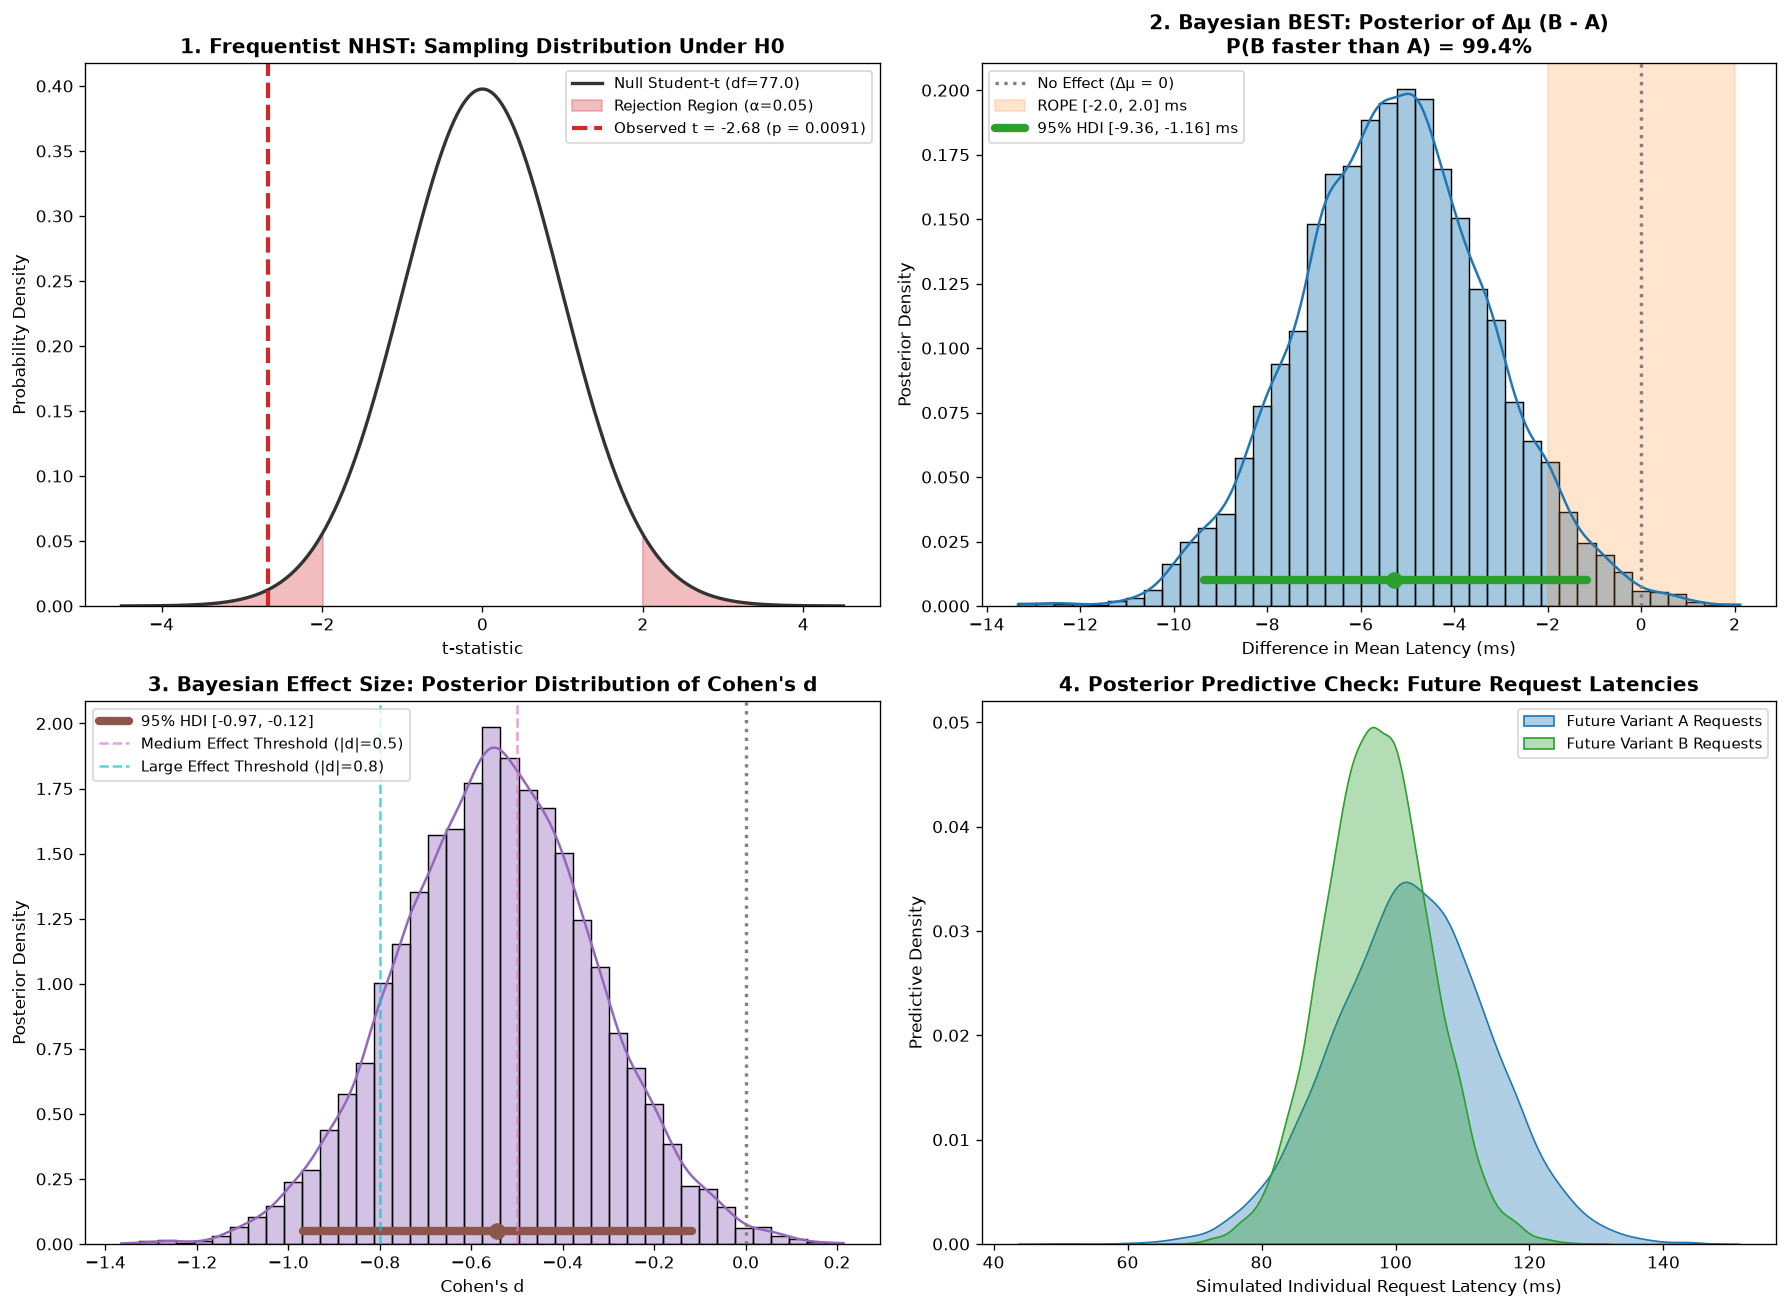

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11), dpi=120)

# -------------------------------------------------------------
# Panel 1: Frequentist Null Distribution & Rejection Region
# -------------------------------------------------------------
ax1 = axes[0, 0]
x_t = np.linspace(-4.5, 4.5, 500)
y_t = stats.t.pdf(x_t, df=df_welch)
ax1.plot(x_t, y_t, color='#333333', lw=2, label=f'Null Student-t (df={df_welch:.1f})')

# Rejection regions (alpha = 0.05 two-sided)
crit_t = stats.t.ppf(0.975, df=df_welch)
ax1.fill_between(x_t, 0, y_t, where=(x_t <= -crit_t), color='#d62728', alpha=0.3, label='Rejection Region (α=0.05)')
ax1.fill_between(x_t, 0, y_t, where=(x_t >= crit_t), color='#d62728', alpha=0.3)

# Observed t-statistic
obs_t = res_welch.statistic
ax1.axvline(obs_t, color='#d62728', lw=2.5, linestyle='--', label=f'Observed t = {obs_t:.2f} (p = {res_welch.pvalue:.4f})')
ax1.set_title("1. Frequentist NHST: Sampling Distribution Under H0", fontsize=12, fontweight='bold')
ax1.set_xlabel("t-statistic")
ax1.set_ylabel("Probability Density")
ax1.legend(loc='upper right', fontsize=9)
ax1.set_ylim(bottom=0)

# -------------------------------------------------------------
# Panel 2: Bayesian Posterior of Difference of Means (Δμ)
# -------------------------------------------------------------
ax2 = axes[0, 1]
sns.histplot(diff_mu_post, stat='density', kde=True, color='#1f77b4', alpha=0.4, bins=40, ax=ax2)
ax2.axvline(0, color='gray', linestyle=':', lw=2, label='No Effect (Δμ = 0)')

# ROPE region
ax2.axvspan(rope_lower, rope_upper, color='#ff7f0e', alpha=0.2, label=f'ROPE [{rope_lower}, {rope_upper}] ms')

# 95% HDI line
ax2.plot([hdi_lower, hdi_upper], [0.01, 0.01], color='#2ca02c', lw=5, solid_capstyle='round', label=f'95% HDI [{hdi_lower:.2f}, {hdi_upper:.2f}] ms')
ax2.scatter([np.mean(diff_mu_post)], [0.01], color='#2ca02c', s=80, zorder=5)

ax2.set_title(f"2. Bayesian BEST: Posterior of Δμ (B - A)\nP(B faster than A) = {prob_b_faster:.1%}", fontsize=12, fontweight='bold')
ax2.set_xlabel("Difference in Mean Latency (ms)")
ax2.set_ylabel("Posterior Density")
ax2.legend(loc='upper left', fontsize=9)

# -------------------------------------------------------------
# Panel 3: Posterior of Standardized Effect Size (Cohen's d)
# -------------------------------------------------------------
ax3 = axes[1, 0]
sns.histplot(cohens_d_post, stat='density', kde=True, color='#9467bd', alpha=0.4, bins=40, ax=ax3)
d_hdi_low, d_hdi_high = np.percentile(cohens_d_post, [2.5, 97.5])
ax3.plot([d_hdi_low, d_hdi_high], [0.05, 0.05], color='#8c564b', lw=5, solid_capstyle='round', 
         label=f'95% HDI [{d_hdi_low:.2f}, {d_hdi_high:.2f}]')
ax3.scatter([np.mean(cohens_d_post)], [0.05], color='#8c564b', s=80, zorder=5)
ax3.axvline(0, color='gray', linestyle=':', lw=2)
ax3.axvline(-0.5, color='#e377c2', linestyle='--', alpha=0.7, label='Medium Effect Threshold (|d|=0.5)')
ax3.axvline(-0.8, color='#17becf', linestyle='--', alpha=0.7, label='Large Effect Threshold (|d|=0.8)')
ax3.set_title("3. Bayesian Effect Size: Posterior Distribution of Cohen's d", fontsize=12, fontweight='bold')
ax3.set_xlabel("Cohen's d")
ax3.set_ylabel("Posterior Density")
ax3.legend(loc='upper left', fontsize=9)

# -------------------------------------------------------------
# Panel 4: Posterior Predictive Checks (Simulated Future Requests)
# -------------------------------------------------------------
ax4 = axes[1, 1]
# Draw 10,000 synthetic future requests accounting for parameter uncertainty
np.random.seed(42)
idx = np.random.choice(len(mu_A_post), size=10000, replace=True)
pred_y_A = np.random.normal(loc=mu_A_post[idx], scale=sigma_A_post[idx])
pred_y_B = np.random.normal(loc=mu_B_post[idx], scale=sigma_B_post[idx])

sns.kdeplot(pred_y_A, fill=True, color='#1f77b4', alpha=0.35, label='Future Variant A Requests', ax=ax4)
sns.kdeplot(pred_y_B, fill=True, color='#2ca02c', alpha=0.35, label='Future Variant B Requests', ax=ax4)
ax4.set_title("4. Posterior Predictive Check: Future Request Latencies", fontsize=12, fontweight='bold')
ax4.set_xlabel("Simulated Individual Request Latency (ms)")
ax4.set_ylabel("Predictive Density")
ax4.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()


---

## Part 5: Variations — Paired $t$-Test & One-Sample $t$-Test

### 5.1 The Paired $t$-Test (Within-Subject Comparison)
When observations are paired—such as benchmarking latency of the **exact same 50 database queries** before and after applying an index:
* **Frequentist**: We compute individual pairwise differences $d_i = y_{\text{post}, i} - y_{\text{pre}, i}$ and run a 1-sample $t$-test testing $H_0: \mu_d = 0$:
  ```python
  stats.ttest_rel(y_post, y_pre)
  ```
* **Bayesian**: A paired $t$-test collapses into an elegant **1-parameter Normal Conjugate updating** problem!
  If $d_i \sim \mathcal{N}(\mu_d, \sigma_d^2)$, with a Normal-Inverse-Gamma prior, the posterior over mean improvement $\mu_d$ is analytical Student-$t$ without requiring any MCMC.

### 5.2 One-Sample $t$-Test
When comparing a single group against a contractual Service Level Objective (SLO), e.g., $\mu \le 100$ ms:
* **Frequentist**: `stats.ttest_1samp(y, popmean=100)`
* **Bayesian**: Fit single Gaussian $(\mu, \sigma)$ and query $P(\mu \le 100 \mid y)$.

> [!NOTE]
> **Deep Dive on Single-Group Estimation**:
> For a rigorous walkthrough of estimating a single population mean, the derivation of $SE = s/\sqrt{n}$, Bessel's correction, the Central Limit Theorem, the "100 Parallel Universes" confidence interval epistemology, and the exact duality between confidence intervals and one-sample hypothesis testing, see the companion sheet: **[📊 Calculating a Mean in a Frequentist World](sheet_calculating_a_mean_in_a_frequentist_world.ipynb)**.

In [8]:
# Demonstration of Paired t-test
np.random.seed(101)
n_queries = 30
query_baseline_complexity = np.random.uniform(50, 200, size=n_queries)

# Post-optimization latency has a true reduction of ~12 ms with query-specific noise
pre_optimization = query_baseline_complexity + np.random.normal(0, 5, size=n_queries)
post_optimization = query_baseline_complexity - 12.0 + np.random.normal(0, 4, size=n_queries)

# Frequentist Paired t-test
paired_res = stats.ttest_rel(post_optimization, pre_optimization)
diffs = post_optimization - pre_optimization

print("==================================================")
print("            PAIRED t-TEST RESULTS                 ")
print("==================================================")
print(f"Mean Pairwise Latency Delta: {diffs.mean():.2f} ms (p-value: {paired_res.pvalue:.4e})")
print(f"95% Paired CI: [{diffs.mean() - stats.t.ppf(0.975, n_queries-1)*stats.sem(diffs):.2f}, "
      f"{diffs.mean() + stats.t.ppf(0.975, n_queries-1)*stats.sem(diffs):.2f}] ms")

# Bayesian Conjugate Update on Differences
# Prior on mu_d ~ Normal(0, 50^2), known or sampled variance
prior_mean, prior_var = 0.0, 50.0**2
sample_var = diffs.var(ddof=1)
n = len(diffs)
post_var = 1.0 / (1.0 / prior_var + n / sample_var)
post_mean = post_var * (prior_mean / prior_var + np.sum(diffs) / sample_var)
post_sd = np.sqrt(post_var)

print(f"Bayesian Posterior Delta Mean: {post_mean:.2f} ms (SD: {post_sd:.2f})")
print(f"P(Post-Optimization is Faster): {stats.norm.cdf(0, loc=post_mean, scale=post_sd):.4%}")


            PAIRED t-TEST RESULTS                 
Mean Pairwise Latency Delta: -11.69 ms (p-value: 1.3714e-11)
95% Paired CI: [-13.92, -9.46] ms
Bayesian Posterior Delta Mean: -11.68 ms (SD: 1.09)
P(Post-Optimization is Faster): 100.0000%


---

## 🎯 Check Your Understanding: 3-Tier Scaffolding Exercises

Practice and solidify your intuition across the three tiers of mastery.

---

### 🟢 Tier 1 (Conceptual Intuition): The Large-N $p$-Value Trap
> **Scenario**: An A/B testing platform runs on 500,000 users per arm.
> The test reports:
> * Control Mean: 45.20 ms
> * Treatment Mean: 45.18 ms
> * Difference: $-0.02$ ms
> * $t = -3.85$, $p = 0.00012$ ($p < 0.001$)
>
> The product manager shouts: *"We have ultra-high statistical significance! Deploy immediately!"*
> 
> **Question**: 
> 1. Why did the $p$-value become so tiny despite the trivial effect?
> 2. How would a Bayesian BEST analysis with a ROPE of $[-0.5, +0.5]$ ms protect the team from shipping an irrelevant optimization?

<details>
<summary><b>🔍 Click here to view the solution & rationale</b></summary>

**Answer**:
1. **The Large-$N$ Trap of NHST**: The standard error is $SE = \frac{s}{\sqrt{n}}$. As $n \to \infty$, $SE \to 0$, which causes the $t$-statistic $t = \frac{\bar{y}_B - \bar{y}_A}{SE}$ to explode to infinity for *any non-zero difference*, no matter how trivial. A $p$-value measures sample size just as much as effect size. Statistical significance $\neq$ Practical significance.
2. **The Bayesian ROPE Protection**: In Bayesian BEST, the posterior difference of means $\Delta\mu$ would be tightly concentrated around $-0.02$ ms with an ultra-narrow 95% HDI like $[-0.03, -0.01]$ ms. Because 100% of the posterior mass falls completely inside the ROPE ($[-0.5, +0.5]$ ms), the Bayesian decision rule explicitly concludes: **The two variants are practically equivalent**. The team saves weeks of engineering maintenance by rejecting an irrelevant change.
</details>

---

### 🟡 Tier 2 (Guided Calculation): Implementing the ROPE Decision Rule
> **Task**: Write a Python function `evaluate_ab_decision(posterior_diff, rope_threshold, min_prob=0.95)` that takes a vector of posterior difference samples and returns a structured decision string:
> * `"SHIP"`: If $P(\Delta\mu < -\text{rope}) \ge \text{min\_prob}$ (High confidence of meaningful improvement)
> * `"EQUIVALENT"`: If $P(|\Delta\mu| \le \text{rope}) \ge \text{min\_prob}$ (High confidence of negligible difference)
> * `"INCONCLUSIVE / GATHER MORE DATA"`: Otherwise.


In [9]:
# ============================================================
# 🟡 Tier 2: Your Turn — Attempt your implementation below!
# ============================================================

def evaluate_ab_decision(posterior_diff, rope_threshold=2.0, min_prob=0.95):
    """
    Evaluates an A/B test decision based on posterior difference samples and a ROPE.
    """
    # TODO: Calculate probability of meaningful improvement (diff < -rope_threshold)
    # TODO: Calculate probability of practical equivalence (|diff| <= rope_threshold)
    # TODO: Return decision
    pass

# Test your function:
# print(evaluate_ab_decision(diff_mu_post, rope_threshold=2.0))


<details>
<summary><b>🔍 Click here to view the Tier 2 solution & code</b></summary>

```python
def evaluate_ab_decision(posterior_diff, rope_threshold=2.0, min_prob=0.95):
    prob_improvement = np.mean(posterior_diff < -rope_threshold)
    prob_equivalent = np.mean(np.abs(posterior_diff) <= rope_threshold)
    prob_regression = np.mean(posterior_diff > rope_threshold)
    
    if prob_improvement >= min_prob:
        return f"🚀 SHIP: {prob_improvement:.1%} probability of meaningful improvement (> {rope_threshold} ms)"
    elif prob_equivalent >= min_prob:
        return f"⏸️ EQUIVALENT: {prob_equivalent:.1%} probability of negligible difference"
    elif prob_regression >= min_prob:
        return f"🛑 ROLLBACK: {prob_regression:.1%} probability of performance regression"
    else:
        return (f"⏳ INCONCLUSIVE: P(Win)={prob_improvement:.1%}, P(Equiv)={prob_equivalent:.1%}. "
                "Gather more telemetry or verify prior assumptions.")

print(evaluate_ab_decision(diff_mu_post, rope_threshold=2.0))
```
</details>


---

### 🔴 Tier 3 (Production Simulation): The "Peeking / Optional Stopping" Trap
> **Scenario**: In real-world experimentation, engineers often "peek" at active A/B tests daily and stop the experiment the moment $p < 0.05$.
> 
> Run the simulation below to demonstrate how optional stopping corrupts Frequentist Type I error (inflating false positives from 5% up to 35%+), while sequential Bayesian updating maintains valid calibration.


In [10]:
# Production Simulation: The Peeking Experiment
np.random.seed(42)
n_simulations = 200
max_samples = 150
peek_every = 5

frequentist_false_positives = 0
bayesian_false_positives = 0

# Under H0: Exactly identical distributions (mu=100, sigma=15 for both!)
for sim in range(n_simulations):
    data_A = np.random.normal(100, 15, size=max_samples)
    data_B = np.random.normal(100, 15, size=max_samples)
    
    freq_stopped = False
    bayes_stopped = False
    
    for n in range(15, max_samples + 1, peek_every):
        sub_A, sub_B = data_A[:n], data_B[:n]
        
        # 1. Frequentist Check
        t_stat, p_val = stats.ttest_ind(sub_B, sub_A, equal_var=True)
        if p_val < 0.05 and not freq_stopped:
            freq_stopped = True
            
        # 2. Bayesian JZS Check (Stopping threshold: BF_10 > 10 strong evidence)
        bf_10, _ = jzs_bayes_factor(t_stat, n, n)
        if bf_10 > 10.0 and not bayes_stopped:
            bayes_stopped = True
            
    if freq_stopped:
        frequentist_false_positives += 1
    if bayes_stopped:
        bayesian_false_positives += 1

print("==================================================")
print("     PEEKING / OPTIONAL STOPPING SIMULATION       ")
print(f"  Simulations: {n_simulations} (True Null H0 is 100% TRUE) ")
print("==================================================")
print(f"Nominal Frequentist Alpha Rate   : 5.0%")
print(f"Actual Frequentist False Alarm % : {frequentist_false_positives / n_simulations:.1%}")
print(f"Bayesian False Alarm % (BF10 > 10): {bayesian_false_positives / n_simulations:.1%}")
print("\nTakeaway: In frequentism, peeking without alpha-spending corrections destroys false-positive guarantees.")
print("Bayes factors naturally penalize small-sample noise via the prior predictive denominator!")


     PEEKING / OPTIONAL STOPPING SIMULATION       
  Simulations: 200 (True Null H0 is 100% TRUE) 
Nominal Frequentist Alpha Rate   : 5.0%
Actual Frequentist False Alarm % : 23.0%
Bayesian False Alarm % (BF10 > 10): 1.5%

Takeaway: In frequentism, peeking without alpha-spending corrections destroys false-positive guarantees.
Bayes factors naturally penalize small-sample noise via the prior predictive denominator!


---

## 🏁 Summary Checklist: Which Test Should You Use?

1. **Use Welch's $t$-test** when:
   * You are required to produce classical $p$-values for external regulatory or peer-reviewed publication standards.
   * You have pre-registered a fixed sample size $N$ and will NOT peek or stop early.
2. **Use JZS Bayes Factors** when:
   * You need to directly choose between $H_0$ and $H_1$.
   * You want to provide positive evidence *for* the null hypothesis ($H_0$).
   * You want to monitor incoming telemetry sequentially.
3. **Use Bayesian BEST Estimation** when:
   * You care about effect sizes, business costs, latency thresholds, and future outcomes.
   * You want intuitive, honest probability statements: $P(\mu_B < \mu_A)$.
   * You want robust modeling (e.g. Student-$t$ likelihood) to protect against production outliers.
   * You have domain prior knowledge to incorporate.

---
**[🏠 Return to Course Home](README.md) | [📊 Foundational Sheet: Estimating a Mean](sheet_calculating_a_mean_in_a_frequentist_world.ipynb)**